In [1]:
run_dir = "data/TOPF_run"

"data/TOPF_run"

In [2]:
using TemperateOptimalPowerFlow
using OrderedCollections, DataFrames, ProgressMeter
using Plots, LaTeXStrings

In [3]:
noise_factors = [replace(file, "P_result_" => "", ".h5" => "") for file ∈ readdir(run_dir) if occursin("P_result", file)]
noise_factors = collect(keys(sort(OrderedDict(noise_factors .=> parse.(Float64, noise_factors)), byvalue=true)))

27-element Vector{String}:
 "0"
 "0.1"
 "0.2"
 "0.3"
 "0.5"
 "0.7"
 "1"
 "1.4"
 "2"
 "3"
 "4"
 "5"
 "7"
 ⋮
 "20"
 "30"
 "40"
 "50"
 "70"
 "100"
 "140"
 "200"
 "300"
 "500"
 "700"
 "1000"

# Distribution of Relative power flowing through the lines

In [4]:
selected_noise_factors = OrderedDict(
    "0"   => "No noise on generation costs",
    "1"   => "Noise with standard deviation 1",
    "10"  => "High noise with standard deviation 10",
    # "100" => "Very high noise with standard deviation 100"
)

issubset(keys(selected_noise_factors), noise_factors)

true

In [5]:
data = Dict{String, Matrix{Float64}}()
@showprogress for noise ∈ keys(selected_noise_factors)
    data[noise] = retrieve_line_flows(run_dir, "P_result_$noise", absolute = true, relative = true)
end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:21


In [6]:
function major_log_ticks(exponent_min::Int, exponent_max::Int)
    ticks = [10.0^i for i = exponent_min:exponent_max]
    labels = [L"10^{%$(i)}" for i = exponent_min:exponent_max]
    (ticks, labels)
end

major_log_ticks (generic function with 1 method)

In [7]:
function minor_log_ticks(exponent_min::Int, exponent_max::Int)
    reduce(vcat, [10.0^i * collect(2:9) for i = exponent_min:exponent_max-1])
end

minor_log_ticks (generic function with 1 method)

In [8]:
noise_colors = Dict(
    "0"  => "darkolivegreen",
    "1"  => "goldenrod",
    "10" => "crimson"
);

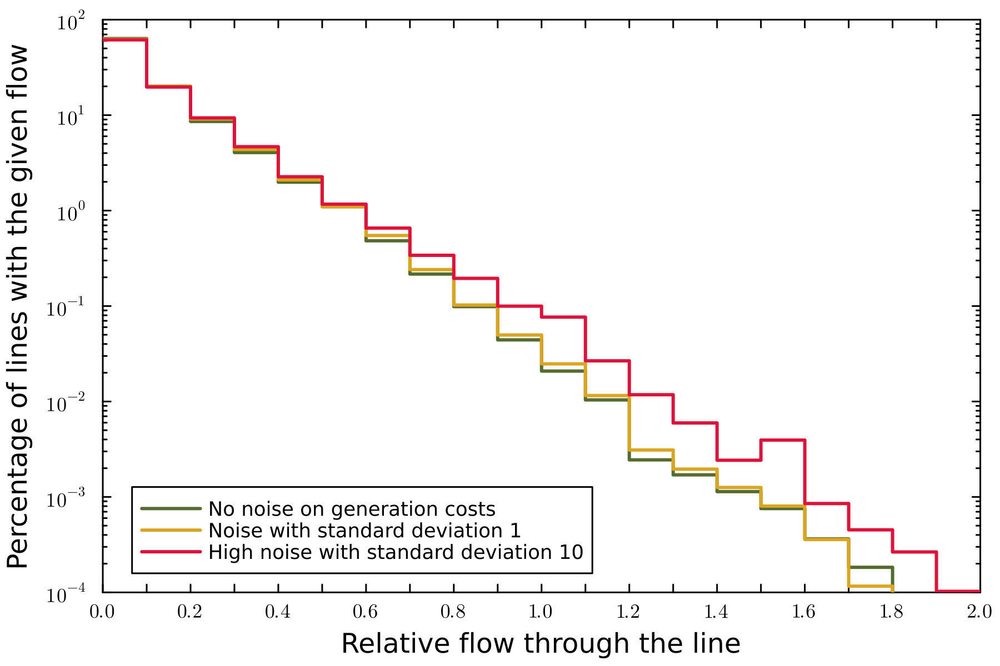

In [9]:
plot(framestyle = :box, dpi=300, legend=:bottomleft,
    xlabel="Relative flow through the line",
    ylabel="Percentage of lines with the given flow",
    xlims=(1e-5,2), x_ticks = ([x/10 for x = 0:20], [(x % 2 == 0) ? latexstring(x / 10) : "" for x = 0:20]),
    ylims=(1e-4, 100), y_ticks = major_log_ticks(-4, 2), yminorticks = minor_log_ticks(-4, 2), grid=false)
for (noise, label) in selected_noise_factors
    stephist!(reshape(data[noise], (length(data[noise]))), label = label, lc = noise_colors[noise],
        weights=repeat([100 / length(data[noise])], length(data[noise])),
        bins=range(0, 2, length=21), linewidth=2, yscale=:log10)
end
savefig("figures/line_flows_distribution.pdf")
plot!()

### Without the four most problematic lines

In [10]:
problematic_lines = [3227, 3310, 5585, 6132]

data_reduced = Dict(noise => table[[i for i = 1:size(table, 1) if i ∉ problematic_lines], :] for (noise, table) ∈ data)

Dict{String, Matrix{Float64}} with 3 entries:
  "1"  => [0.0555183 0.0553844 … 0.0514645 0.0549159; 0.0555183 0.0553844 … 0.0…
  "10" => [0.0555183 0.0553844 … 0.0514645 0.0549159; 0.0555183 0.0553844 … 0.0…
  "0"  => [0.018925 0.0186583 … 0.0433476 0.0397089; 0.018925 0.0186583 … 0.043…

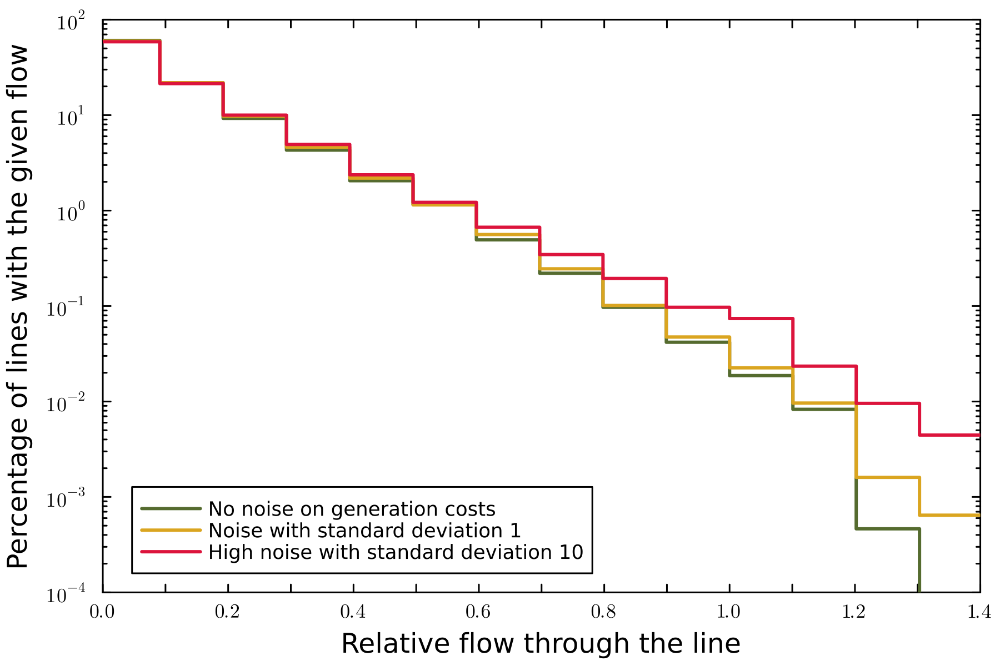

In [11]:
plot(framestyle = :box, dpi=300, legend=:bottomleft,
    xlabel="Relative flow through the line",
    ylabel="Percentage of lines with the given flow",
    xlims=(0, 1.4), x_ticks = ([x/10 for x = 0:14], [(x % 2 == 0) ? latexstring(x / 10) : "" for x = 0:14]),
    ylims=(1e-4, 100), y_ticks = major_log_ticks(-4, 2), yminorticks = minor_log_ticks(-4, 2), grid=false)
for (noise, label) in selected_noise_factors
    stephist!(reshape(data_reduced[noise], (length(data_reduced[noise]))), label = label, lc = noise_colors[noise],
        weights=repeat([100 / length(data_reduced[noise])], length(data_reduced[noise])),
        bins=range(-0.01, 2.01, length=21), linewidth=2, yscale=:log10)
end
plot!()

# Counting lines above threshold

In [12]:
thresholds = Dict(
    "above80"  => 0.8,
    "above100" => 1.0,
    "above120" => 1.2
    )

Dict{String, Float64} with 3 entries:
  "above100" => 1.0
  "above120" => 1.2
  "above80"  => 0.8

In [13]:
line_flows_thresholds = DataFrame(noise = Vector{Float64}())
for threshold ∈ keys(thresholds)
    line_flows_thresholds[!, threshold] = Vector{Float64}()
end
@showprogress for noise in noise_factors
    table = retrieve_line_flows(run_dir, "P_result_$noise", absolute = true, relative = true)
    df = DataFrame(Dict(key => sum(table .> threshold) / length(table) for (key, threshold) ∈ thresholds))
    df[!, "noise"] = [parse(Float64, noise)]
    append!(line_flows_thresholds, df)
end
line_flows_thresholds

Progress: 100%|█████████████████████████████████████████| Time: 0:03:39


Row,noise,above100,above120,above80
,Float64,Float64,Float64,Float64
1,0.0,0.000378301,6.62348e-5,0.00180574
2,0.1,0.000378547,6.5155e-5,0.00180279
3,0.2,0.000379818,6.33235e-5,0.00180116
4,0.3,0.000382675,6.1615e-5,0.00180764
5,0.5,0.000396602,6.17243e-5,0.00183075
6,0.7,0.000413742,6.65628e-5,0.00187162
7,1.0,0.000439314,7.6144e-5,0.00196079
8,1.4,0.000477475,9.0796e-5,0.00214182
9,2.0,0.00055254,0.000111284,0.00245993


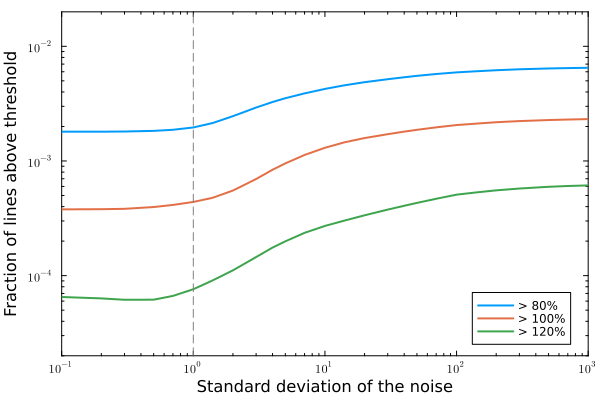

In [14]:
plot(line_flows_thresholds.noise[2:end], line_flows_thresholds.above80[2:end], label = "> 80%", linewidth=2, framestyle=:box,
    xlims=(0.1, 1000), x_ticks = major_log_ticks(-1, 3), xminorticks = minor_log_ticks(-1, 3), xscale=:log10,
    ylims=(2e-5, 2e-2), y_ticks = major_log_ticks(-4, -2), yminorticks = minor_log_ticks(-5, -2), yscale=:log10,
    xlabel="Standard deviation of the noise", ylabel="Fraction of lines above threshold",
    legend=:bottomright, grid=false)
plot!(line_flows_thresholds.noise[2:end], line_flows_thresholds.above100[2:end], label = "> 100%", linewidth=2)
plot!(line_flows_thresholds.noise[2:end], line_flows_thresholds.above120[2:end], label = "> 120%", linewidth=2)
vline!([1], linestyle=:dash, seriescolor = :gray, label="")
savefig("figures/line_flows_thresholds.pdf")
plot!()

# Comparison for individual generators

In [15]:
gen_data = Dict{String, Matrix{Float64}}()
for noise ∈ keys(selected_noise_factors)
    gen_data[noise] = 100 * retrieve_gen_results(run_dir, "P_result_$noise")
end

In [16]:
network = import_model("../models/europe.json")

Dict{String, Any} with 12 entries:
  "gen_nd"   => Dict{String, Any}()
  "bus"      => Dict{String, Any}("4304"=>Dict{String, Any}("coord"=>Any[11.843…
  "name"     => "europe"
  "dcline"   => Dict{String, Any}()
  "gen"      => Dict{String, Any}("1"=>Dict{String, Any}("entsoe_names"=>Any[],…
  "branch"   => Dict{String, Any}("4304"=>Dict{String, Any}("br_r"=>0.00174284,…
  "storage"  => Dict{String, Any}()
  "switch"   => Dict{String, Any}()
  "baseMVA"  => 100
  "per_unit" => true
  "shunt"    => Dict{String, Any}()
  "load"     => Dict{String, Any}("4304"=>Dict{String, Any}("load_bus"=>4304, "…

In [17]:
gen_ids = get_ordered_gen_ids(network);

In [18]:
function plot_gen(id::String, gen_name::String; week::Int = 0, noise_levels = ["1", "0"])
    i = findfirst(==(id), gen_ids)
    range = week > 0 ? (168*(week-1)+1:168*week) : (1:8736)
    x = (collect(range) .- first(range)) / 24
    plot(framestyle = :box, dpi=300, legend=:topright, xlabel="Time [days]", ylabel="Power output [MW]", title=gen_name,
        xlims=(0, (last(range) - first(range) + 1) / 24), ylims=(0, 120 * network["gen"][id]["pmax"]))
    for noise in noise_levels
        plot!(x, gen_data[noise][i, range], label = selected_noise_factors[noise], lc = noise_colors[noise])
    end
    plot!()
end

plot_gen (generic function with 1 method)

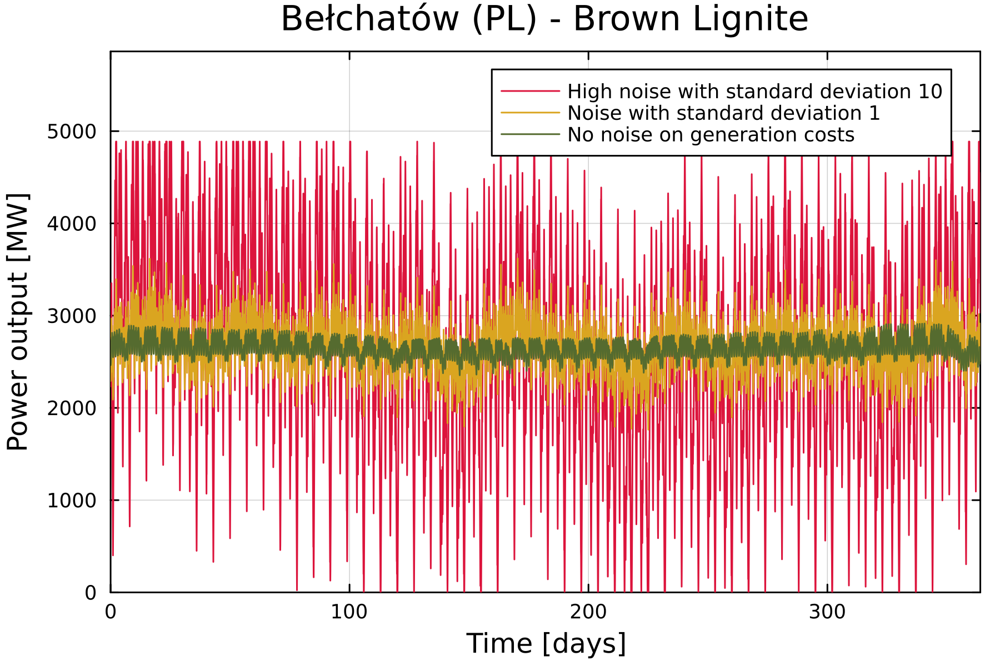

In [19]:
plot_gen("325", "Bełchatów (PL) - Brown Lignite", noise_levels = ["10", "1", "0"])

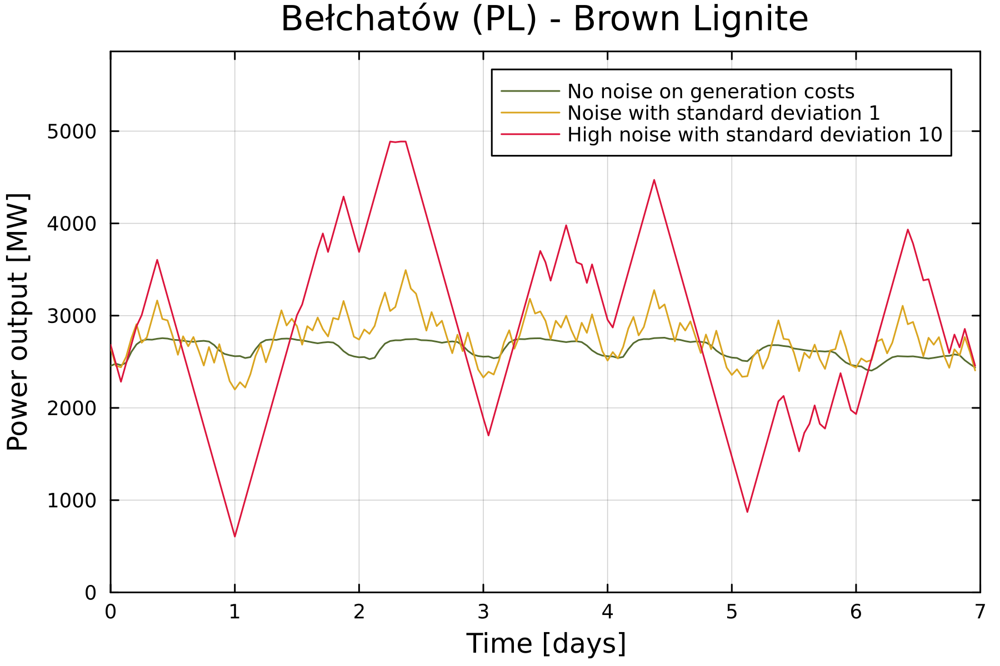

In [20]:
plot_gen("325", "Bełchatów (PL) - Brown Lignite", week=26, noise_levels = ["0", "1", "10"])

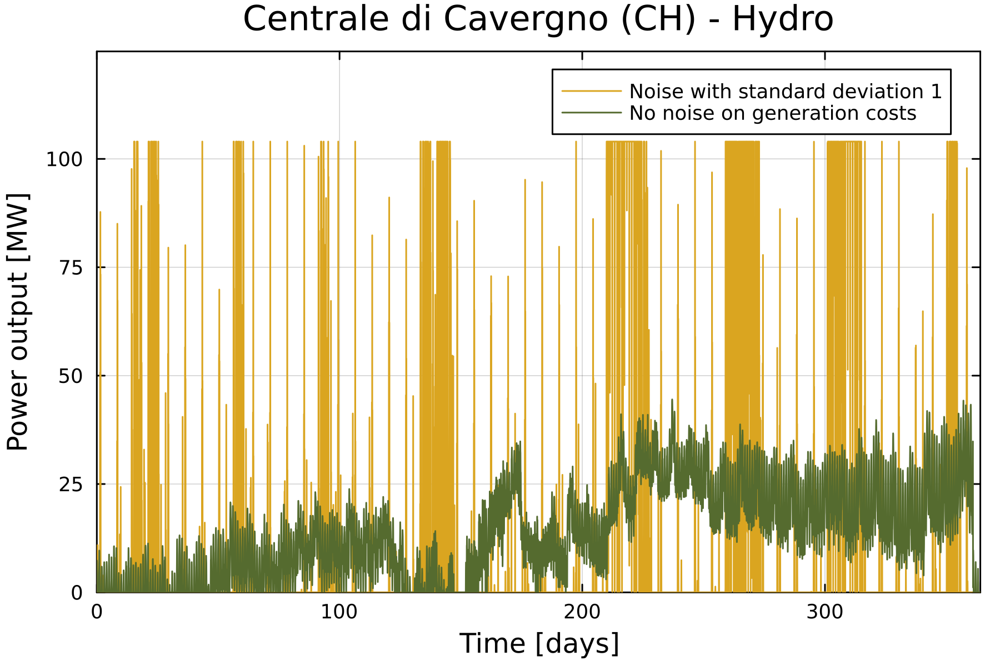

In [21]:
plot_gen("923", "Centrale di Cavergno (CH) - Hydro")

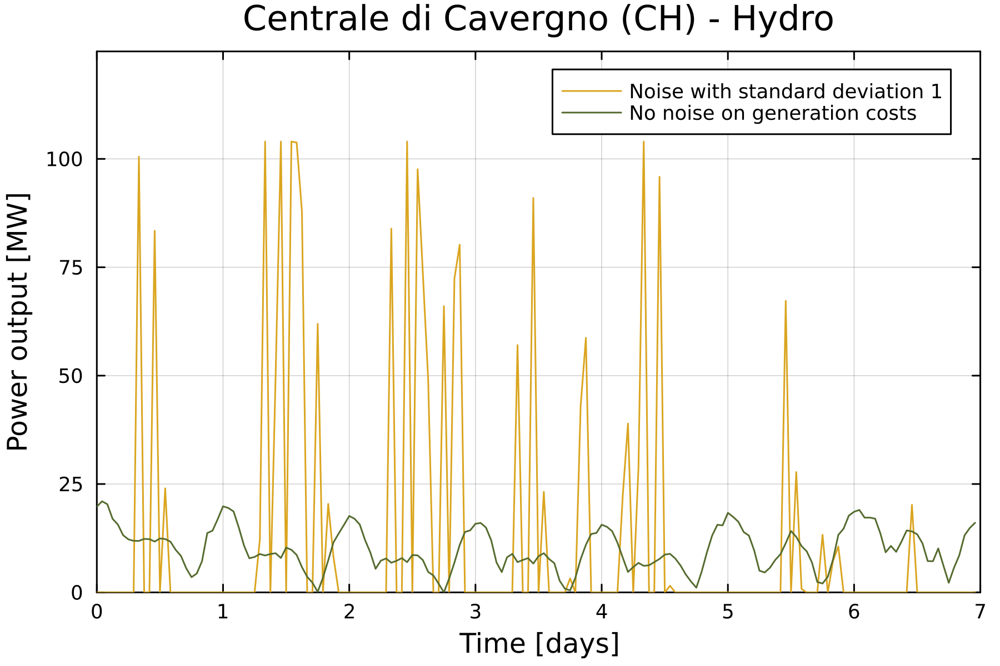

In [22]:
plot_gen("923", "Centrale di Cavergno (CH) - Hydro", week=14)

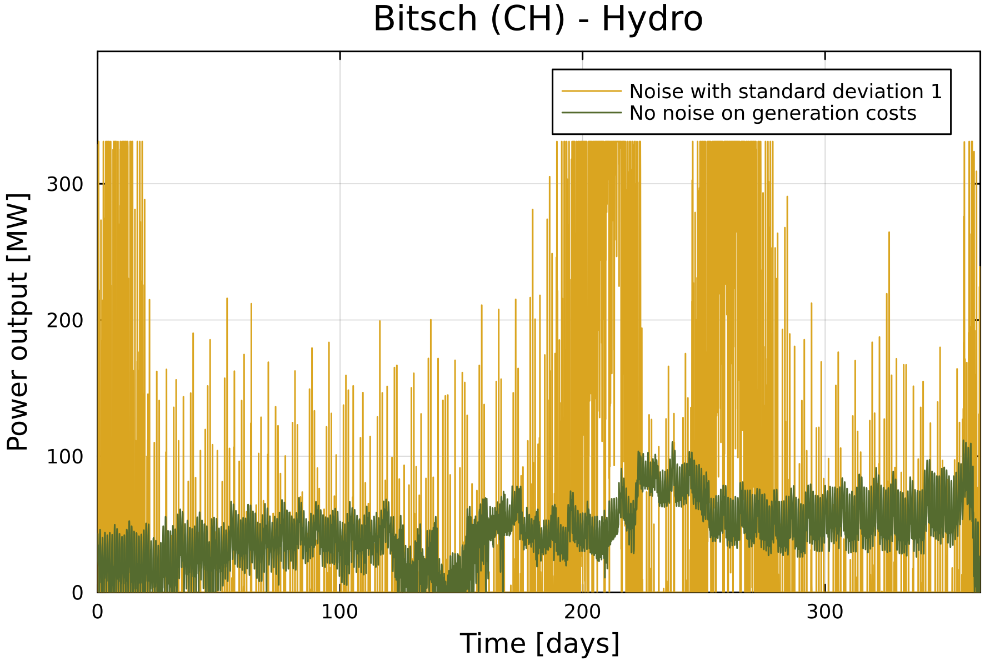

In [23]:
plot_gen("916", "Bitsch (CH) - Hydro")

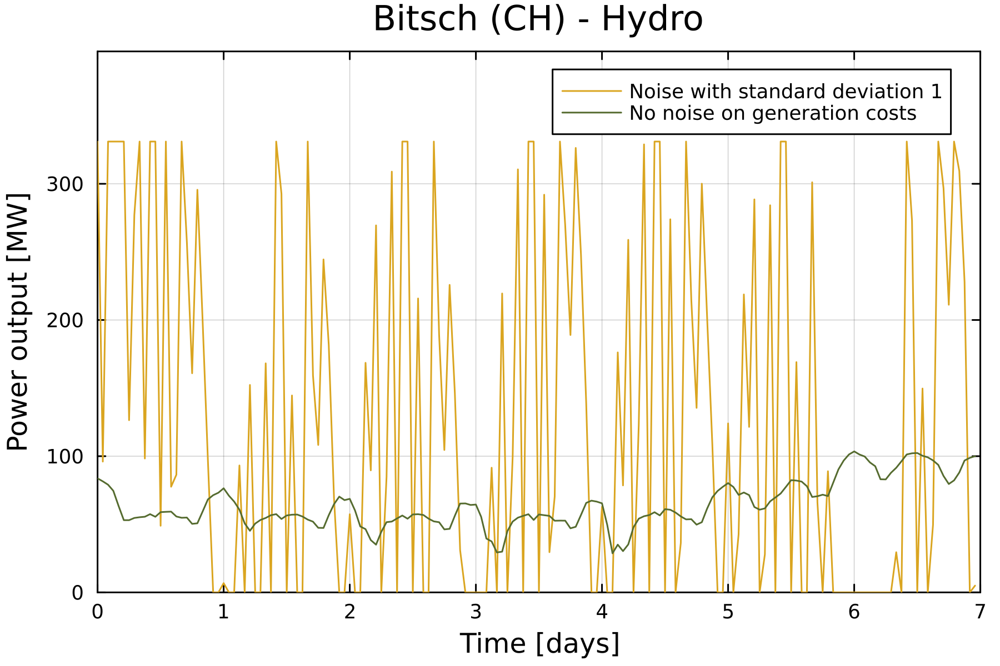

In [24]:
plot_gen("916", "Bitsch (CH) - Hydro", week=32)

In [25]:
# i = findfirst(==("916"), gen_ids)
# export_data = hcat(gen_data["0"][i, :], gen_data["1"][i, :])

# using CSV
# CSV.write("data/noise_comparison_Bitsch.csv", CSV.Tables.table(export_data), header=false)

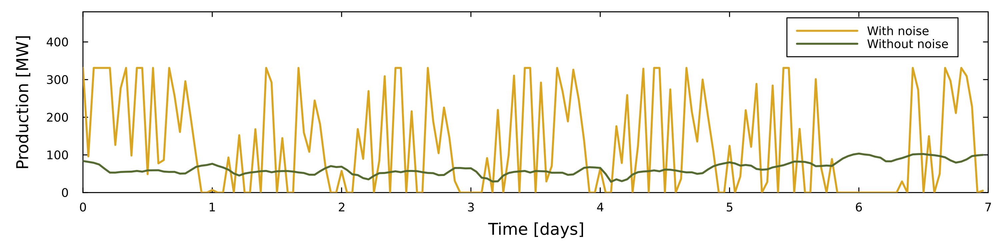

In [26]:
i = findfirst(==("916"), gen_ids)
week = 32
trange = (168*(week-1)+1:168*week)
x = 0:1/24:7-1/24
plot(x, gen_data["1"][i, trange], label = "With noise", lc = noise_colors["1"], lw = 2,
    xlims=(0, 7), ylims=(0, 480), xlabel="Time [days]", ylabel="Production [MW]",
    size=(1000, 250), framestyle = :box, dpi=300, legend=:topright,
    left_margin=8Plots.mm, bottom_margin=8Plots.mm, grid=false)
plot!(x, gen_data["0"][i, trange], label = "Without noise", lc = noise_colors["0"], lw = 2)
savefig("figures/noise_comparison_Bitsch.pdf")
plot!()

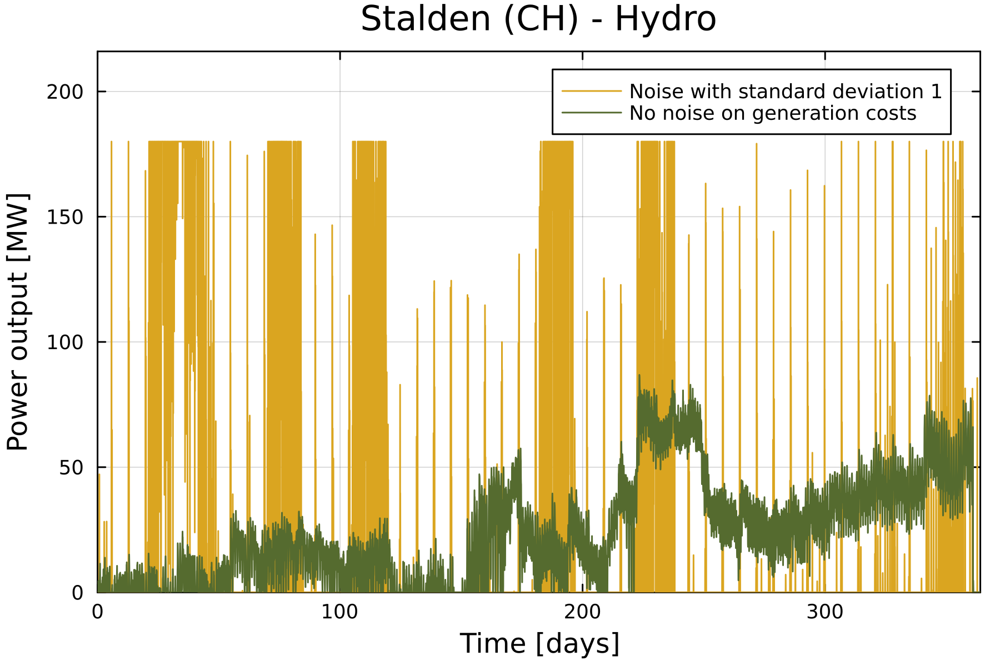

In [27]:
plot_gen("915", "Stalden (CH) - Hydro")

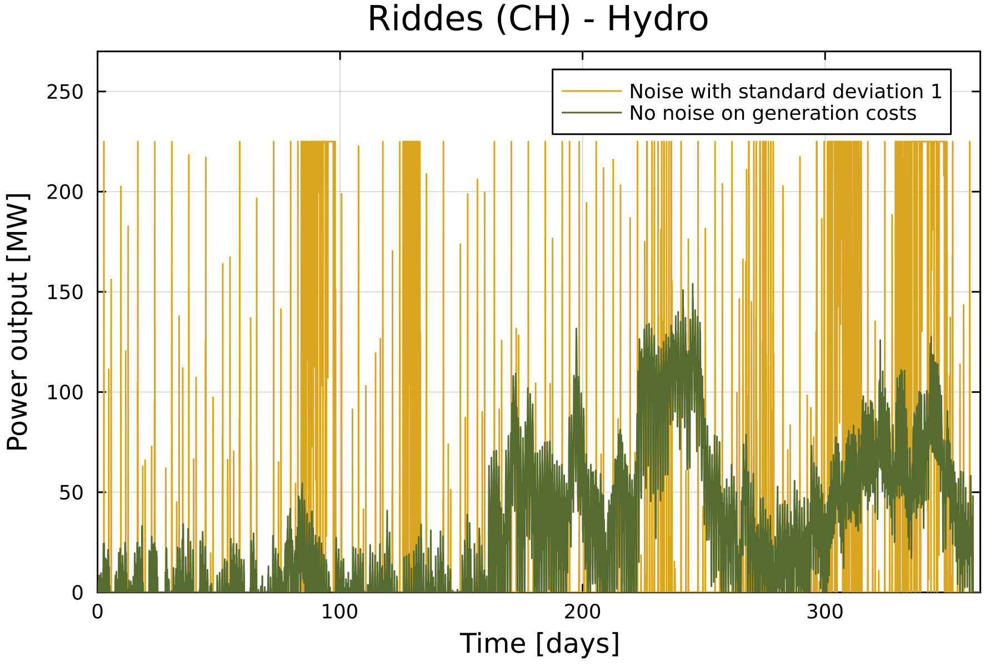

In [28]:
plot_gen("173", "Riddes (CH) - Hydro")

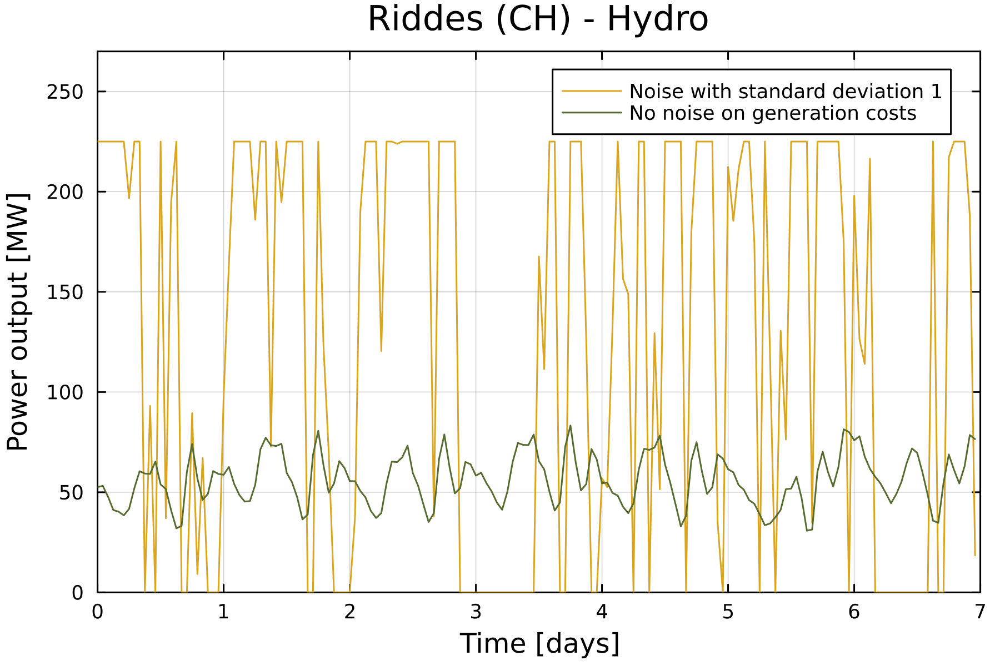

In [29]:
plot_gen("173", "Riddes (CH) - Hydro", week = 45)

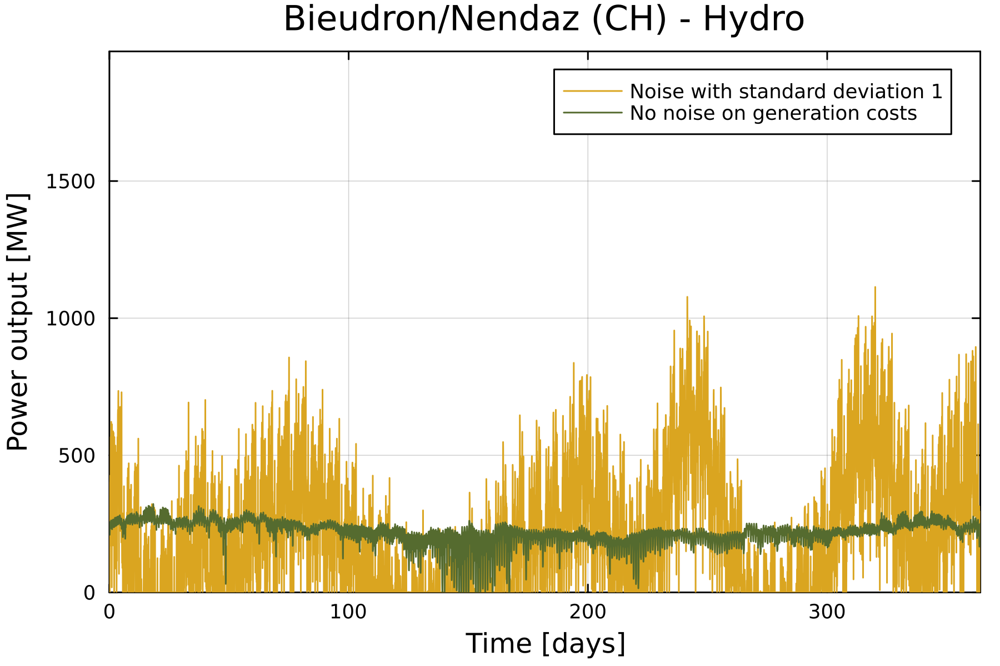

In [30]:
plot_gen("914", "Bieudron/Nendaz (CH) - Hydro")

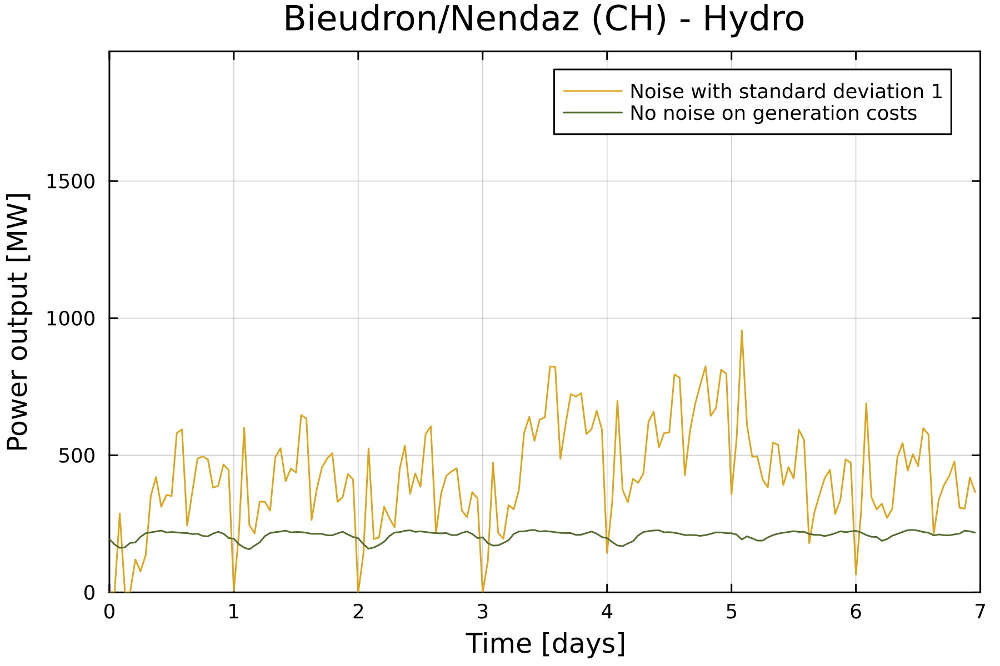

In [31]:
plot_gen("914", "Bieudron/Nendaz (CH) - Hydro", week=34)

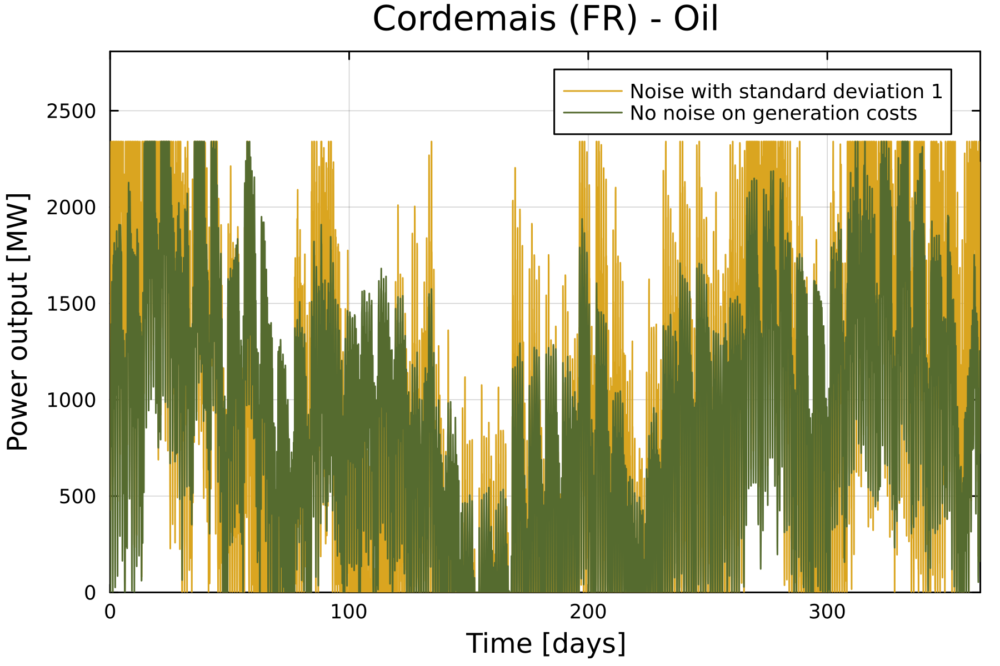

In [32]:
plot_gen("711", "Cordemais (FR) - Oil")